#### This is a dataset consisting of restaurant reviews. Your goal is to predict the `stars` column.
Adapted from Katie Sylvia

#### Imports

In [2]:
import numpy as np
import pandas as pd       
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

import nltk
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('data/restaurant_reviews.csv', index_col = 0)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   stars   10000 non-null  int64 
 1   text    10000 non-null  object
dtypes: int64(1), object(1)
memory usage: 234.4+ KB


In [5]:
df = df.sample(8000, random_state=404)

#### Check baseline

In [6]:
df['stars'].value_counts(normalize=True)

stars
4    0.353375
5    0.332250
3    0.149000
2    0.091375
1    0.074000
Name: proportion, dtype: float64

In [7]:
# I need more 1 and 2 star reviews!

In [8]:
df['stars'] = df['stars'].map({1:'1 star', 2:'2 stars', 3:'3 stars', 4:'4 stars', 5:'5 stars'})

#### Sentiment analysis

In [9]:
# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

def get_sentiment_score(sentence):
    scores = analyzer.polarity_scores(sentence)
    return scores['compound']  # Compound score is a normalized score [-1, 1]

get_sentiment_score("I love food!"), get_sentiment_score("I hate food!"), get_sentiment_score("food is okay")

(0.6696, -0.6114, 0.2263)

What if I wanted to include the sentiment score as a feature in my model?

In [10]:
df['nltk_sentiment'] = df['text'].apply(lambda x:get_sentiment_score(x))
df['nltk_sentiment'].head()

1860    0.9371
4182    0.9545
8726    0.9544
1892    0.6934
8044    0.9983
Name: nltk_sentiment, dtype: float64

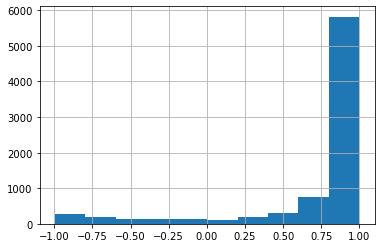

In [127]:
df.nltk_sentiment.hist();

In [128]:
get_sentiment_score("sick burrito! That food was fire")

-0.7177

In [129]:
get_sentiment_score("I got sick! The food was on fire")

-0.7177

In [130]:
analyzer.polarity_scores("sick burrito! That food was fire")

{'neg': 0.6, 'neu': 0.4, 'pos': 0.0, 'compound': -0.7177}

In [131]:
analyzer.polarity_scores("I got sick! The food was on fire")

{'neg': 0.545, 'neu': 0.455, 'pos': 0.0, 'compound': -0.7177}

In [132]:
# Custom sentiment scores?

analyzer.lexicon['fire'] = 0.7 
analyzer.lexicon['fire']

0.7

#### Tangent

Who's speaking (or writing), and how might this differ from the language your language model was trained on?

[huggingface](https://huggingface.co/cardiffnlp/twitter-roberta-base)

In [133]:
data = ["Sick burrito! that food was fire", "I got sick! The food was on fire"]

[get_sentiment_score(i) for i in data]

[-0.4389, -0.4389]

In [134]:
from transformers import pipeline
# Initialize the sentiment analysis pipeline
sentiment_pipeline = pipeline("sentiment-analysis", model="finiteautomata/bertweet-base-sentiment-analysis")

# Perform sentiment analysis
sentiment_pipeline(data)

emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


[{'label': 'POS', 'score': 0.43658867478370667},
 {'label': 'NEG', 'score': 0.9797215461730957}]

In [135]:
from transformers import pipeline, AutoModelForSequenceClassification, AutoTokenizer

# Setup
model_name = "finiteautomata/bertweet-base-sentiment-analysis"
model = AutoModelForSequenceClassification.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Sentiment analysis pipeline
analyzer = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

# Perform sentiment analysis
results = analyzer(data)

# Results
for text, result in zip(texts, results):
    print(f"Text: {text}")
    print(f"Sentiment: {result['label']}, Score: {result['score']:.4f}")

emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


Text: Sick burrito! that food was fire
Sentiment: POS, Score: 0.4366
Text: I got sick! The food was on fire
Sentiment: NEG, Score: 0.9797


This is important for validity. [This](https://dl.acm.org/doi/10.1145/3531146.3533144) was a big issue!

#### Train Test Split

In [11]:
X = df[['text', 'nltk_sentiment']]
y = df['stars']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=404)

In [13]:
X_train

,text,nltk_sentiment
4574,I will tell you exactly why this place is so g...,0.8372
2222,No need for a long review.\r\n\r\nEvery In-N-O...,0.9432
9773,"Alright, so how does it go from being a 1-star...",0.9645
7327,"Delicious, cheap (for how much you actually ge...",0.9745
6264,This is my current first choice in eateries. ...,0.9816
...,...,...
4970,Truly don't appreciate the pathetic TEASE they...,0.9661
4926,"I don't drink, so my review will not be intoxi...",0.8950
1995,This place is a most see must do during xmas t...,0.8268
2578,Fabulous! This was my son- in -laws Restaurant...,0.9020


#### Pipeline

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ('text_vectorizer', CountVectorizer(stop_words='english', min_df=0.1), 'text')  # CountVectorizer for text column
    ],
    remainder='passthrough'
)

# min df is a proportion if you pass a float, an absolute number of documents if you pass an integer.

In [15]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))  # Remember, default is l2
])

In [16]:
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('text_vectorizer',
                                                  CountVectorizer(min_df=0.1,
                                                                  stop_words='english'),
                                                  'text')])),
                ('logreg', LogisticRegression(max_iter=1000))])

My `text` column was passed through my preprocessor, and my `sentiment` column was passed through unaltered as the remainder. 

#### Score on training and testing set

In [17]:
pipe.score(X_train, y_train), pipe.score(X_test, y_test)

(0.485, 0.461)

It looks a little overfit! We could try reducing dimensionality:

- min_df
- max_df

In [18]:
# Generate predictions on the test set
y_pred = pipe.predict(X_test)

# Compute classification report
report = classification_report(y_test, y_pred)

# Print the report
print(report)

              precision    recall  f1-score   support

      1 star       0.46      0.52      0.49       149
     2 stars       0.28      0.11      0.16       199
     3 stars       0.21      0.10      0.13       263
     4 stars       0.45      0.52      0.48       705
     5 stars       0.53      0.63      0.57       684

    accuracy                           0.46      2000
   macro avg       0.39      0.37      0.37      2000
weighted avg       0.43      0.46      0.44      2000



In [19]:
# talk about OvR

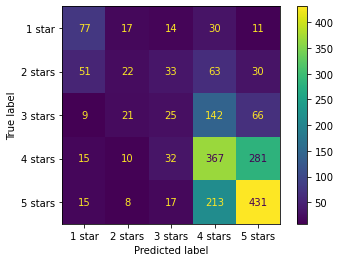

In [20]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

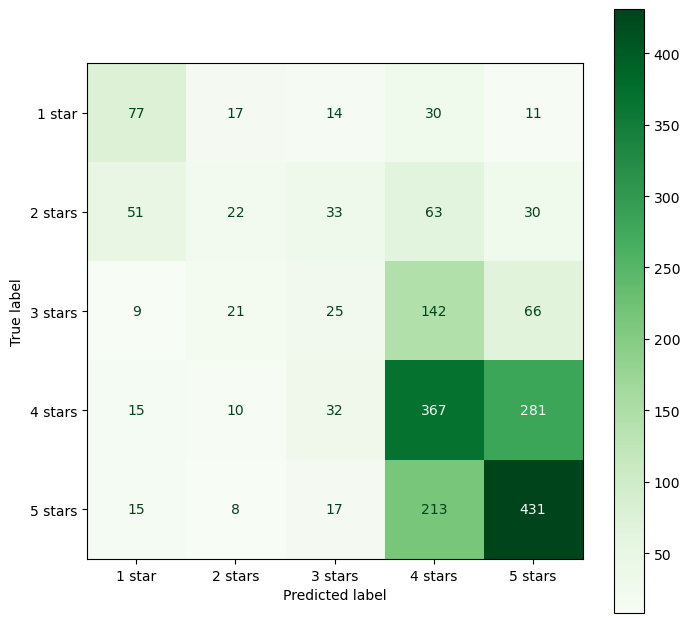

In [21]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, cmap='Greens', ax=ax, text_kw={'fontsize': 10});

In [22]:
# Start here

#### One more...

In [56]:
# Let's create a custom transformer

from nltk.stem import WordNetLemmatizer 
from nltk.corpus import wordnet

def custom_lemmatize(word, tag):
    lemmatizer = WordNetLemmatizer()
    mapper = {
        'J': wordnet.ADJ,
        'V': wordnet.VERB,
        'N': wordnet.NOUN,
        'R': wordnet.ADV
    }
    pos = mapper.get(tag[0])
    return lemmatizer.lemmatize(word, pos) if pos else word

def lemmatize(text):
    tokens = text.split(" ")
    lemmatized_tokens = [custom_lemmatize(word, tag) for word, tag in nltk.pos_tag(tokens)]
    return ' '.join(lemmatized_tokens)

pros: I can gridsearch over preprocessing steps.

In [57]:
# CT

preprocessor = ColumnTransformer(
    transformers=[
        ('tvec', TfidfVectorizer(stop_words='english', preprocessor = lemmatize, min_df=.04, max_df=.5, ngram_range=(1,1)), 'text'), 
    ],
    remainder='passthrough'
)

In [58]:
# Pipe

pipe2 = Pipeline([
    ('preprocessor', preprocessor), 
    ('logreg', LogisticRegression(max_iter=1000, penalty=None))
])

pipe2.fit(X_train, y_train)
pipe2.score(X_train, y_train), pipe2.score(X_test, y_test)

/Users/rowanschaefer/opt/anaconda3/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:408: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['far', 'make'] not in stop_words.
  warnings.warn(


(0.5656666666666667, 0.4885)

In [60]:
# Gridsearch

from sklearn.model_selection import RandomizedSearchCV

# Param dict
params = {
    'preprocessor__tvec__max_df': [0.5, 0.7]
}

In [ ]:
rcv = RandomizedSearchCV(pipe2, params, n_iter=100, cv=5)
rcv.fit(X_train, y_train)

/Users/rowanschaefer/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_search.py:307: UserWarning: The total space of parameters 2 is smaller than n_iter=100. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/Users/rowanschaefer/opt/anaconda3/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:408: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['far', 'make'] not in stop_words.
  warnings.warn(


In [ ]:
cv_results_

reduce overfitting
- tfidfvectorizer prioritizes rare words - add min_df to ignore super rare ones.

improve accuracy
- limit dimensionality - max_df, max_features
- add ngrams

In [ ]:
# Break it down
# What matters most? It depends!

In [97]:
from sklearn.metrics import classification_report

y_pred = pipe2.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

      1 star       0.54      0.48      0.51        73
     2 stars       0.38      0.15      0.21        87
     3 stars       0.24      0.08      0.12       147
     4 stars       0.47      0.61      0.53       361
     5 stars       0.51      0.59      0.55       332

    accuracy                           0.48      1000
   macro avg       0.43      0.38      0.39      1000
weighted avg       0.45      0.48      0.45      1000



In [ ]:
# When should I use f1 score?

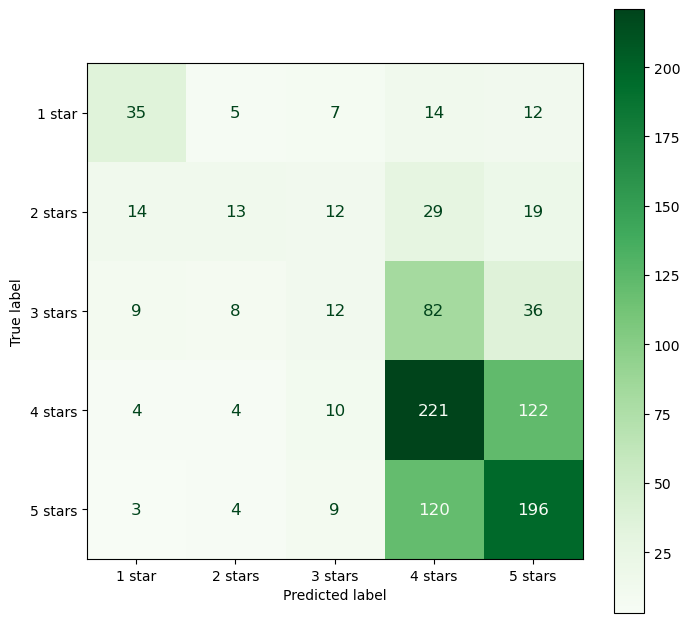

In [104]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
ConfusionMatrixDisplay.from_estimator(pipe2, X_test, y_test, cmap = 'Greens', ax=ax, text_kw={'fontsize': 12});

#### What else?

Let's make another column of text.

In [251]:
def extract_urls(text):
    urls = pd.Series(text).str.extract(r'(https?://\S+|www\.\S+)')
    return urls.dropna().values.flatten().tolist()

In [252]:
df['url'] = df['text'].apply(extract_urls)

Apply different preprocessing to 'text' and 'url' columns

In [232]:
preprocessor_text = ColumnTransformer(
    transformers=[
        ('text_vectorizer', CountVectorizer(stop_words='english', min_df=.04, max_df=.8, ngram_range=(1,2)), 'text'),
        ('url_vectorizer', CountVectorizer(), 'url')
    ],
    remainder='passthrough'
)

preprocessor_url = ColumnTransformer(
    transformers=[
        ('url_vectorizer', CountVectorizer()), 'url') 
    ],
    remainder='passthrough'
)

In [233]:
pipe2 = Pipeline([
    ('preprocessor', preprocessor), 
    ('logreg', LogisticRegression(max_iter=1000, solver='saga'))
])

pipe2.fit(X_train, y_train)
pipe2.score(X_train, y_train), pipe2.score(X_test, y_test)

(0.5695, 0.4875)

#### Feature importances

In [105]:
# Column names
words = pipe2.named_steps['preprocessor'].named_transformers_['text_vectorizer'].get_feature_names_out()

# Coefs
coefs = pipe2.named_steps['logreg'].coef_
coefs[0], coefs[1]

# Why do I have 5 lists of coefs? I have 5 classes

(array([ 0.348196  , -0.41880095, -0.45399349,  0.61112145,  0.66821342,
        -0.11269653, -0.53800816,  0.78555916,  0.39104727,  0.90124037,
         0.61510773, -0.48448587, -1.39662507,  0.70966438, -0.38233179,
         0.99114374, -1.8575189 ,  0.44811489, -0.09844409, -0.09665301,
        -0.90063287,  0.18444127, -0.89677208, -0.68534346,  0.27200152,
        -0.20329898, -0.21730645,  0.02246486,  0.33076223,  1.54765775,
         0.56403848,  0.41202903, -0.35085139, -0.38918456,  1.21316371,
         0.28495456,  0.79500871,  0.98563773,  1.45221281,  0.44926903,
        -0.20711783, -0.35265529,  0.10014659, -0.42185166, -0.19791635,
        -0.10688939,  0.58817011,  0.66988684, -1.63980683]),
 array([-0.42976668,  0.01819629,  1.62837942, -0.31817341, -0.17578533,
        -0.21829777, -1.20433772,  0.47535723,  0.67394904,  0.0336801 ,
         0.43154186, -0.91826017, -0.10013585,  0.38576576,  0.37860674,
         0.22944779, -0.73529893,  0.7135213 ,  0.24893068,  1

In [106]:
coefs[4] # 5 star reviews

# add sentiment score to my array of features
words = np.append(words, 'sentiment score')

In [108]:
# Most predictive of 5 star review

pd.DataFrame(coefs[4], index=words).sort_values(by=0, ascending = False).head()

,0
sentiment score,1.709669
love,1.659992
delicious,1.223709
great,1.193279
best,1.128595


In [117]:
# Most predictive of 1 star review

pd.DataFrame(coefs[1], index=words).sort_values(by=0, ascending = False).head()

,0
better,1.628379
like,1.215308
night,0.904819
just,0.713521
didn,0.673949


You can't interpret these like regular coefs! Instead you can talk about relative importance.

In [118]:
# What if I want to aggregate my predictions from multiple models?

from sklearn.ensemble import VotingClassifier
voting_clf = VotingClassifier(estimators=[('pipe', pipe), ('pipe2', pipe2)], voting='soft')

voting_clf.fit(X_train, y_train)
y_pred = voting_clf.predict(X_test)

report = classification_report(y_test, y_pred)
print(report)

# 'hard' for majority voting, 'soft' for averaging predicted probabilities.

NameError: name 'labels' is not defined

#### Next steps...
- Gridsearch
- Text preprocessing functions
- Try new models (coming soon!)